# HR Analytics: Employee Attrition Analysis

## Project Overview
This project explores employee attrition using the IBM HR Analytics Employee Attrition & Performance dataset. The goal is to identify patterns in employee turnover and examine how attrition varies across job roles, demographics, job satisfaction, compensation, tenure, and working conditions.

## Business Problem
Employee turnover can affect workforce stability, productivity, and recruitment costs. This analysis investigates which employee groups have higher attrition rates and identifies patterns that may help inform employee-retention strategies.

## Objectives
- Analyze overall employee attrition.
- Compare attrition across departments and job roles.
- Explore relationships between attrition, satisfaction, tenure, and working conditions.
- Identify key findings and develop data-informed business recommendations.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn.

## Dataset
The original dataset contains 1,470 rows and 35 columns. The target variable is `Attrition`, indicating whether an employee left (`Yes`) or stayed (`No`).

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/employee_attrition.csv')

In [74]:
df.shape

(1470, 35)

In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [76]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [77]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [78]:
df.isnull().sum().sum()

np.int64(0)

In [79]:
df.duplicated().sum()

np.int64(0)

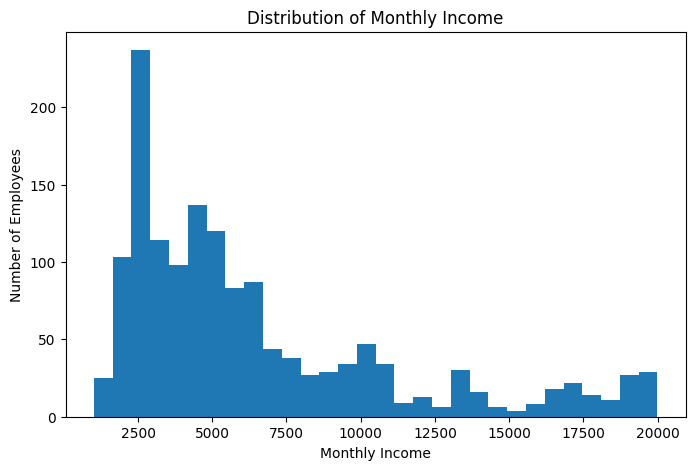

In [80]:
plt.figure(figsize=(8, 5))
plt.hist(df['MonthlyIncome'], bins=30)
plt.xlabel('Monthly Income')
plt.ylabel('Number of Employees')
plt.title('Distribution of Monthly Income')
plt.show()

In [81]:
Q1 = df['MonthlyIncome'].quantile(0.25)
Q3 = df['MonthlyIncome'].quantile(0.75)

IQR = Q3 - Q1

Lower_Bound = Q1 - 1.5 * IQR
Upper_Bound = Q3 + 1.5 * IQR

outliers = df[(df['MonthlyIncome'] < Lower_Bound) | (df['MonthlyIncome'] > Upper_Bound)]

outliers_count = outliers.shape[0]
outliers_percentage = (outliers_count / df.shape[0]) * 100
print(f"Number of outliers in MonthlyIncome: {outliers_count}")
print(f"Percentage of outliers in MonthlyIncome: {outliers_percentage:.2f}%")

Number of outliers in MonthlyIncome: 114
Percentage of outliers in MonthlyIncome: 7.76%


In [82]:
outliers['MonthlyIncome'].describe()

count      114.000000
mean     18399.666667
std       1093.085190
min      16595.000000
25%      17345.750000
50%      18716.500000
75%      19376.750000
max      19999.000000
Name: MonthlyIncome, dtype: float64

In [83]:
df['Attrition'].value_counts(normalize=True)*100

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

In [84]:
df.groupby('Department')['Attrition'].value_counts()

Department              Attrition
Human Resources         No            51
                        Yes           12
Research & Development  No           828
                        Yes          133
Sales                   No           354
                        Yes           92
Name: count, dtype: int64

In [85]:
attrition_by_dept =df.groupby('Department')['Attrition'].value_counts(normalize=True).unstack() * 100
attrition_by_dept

Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


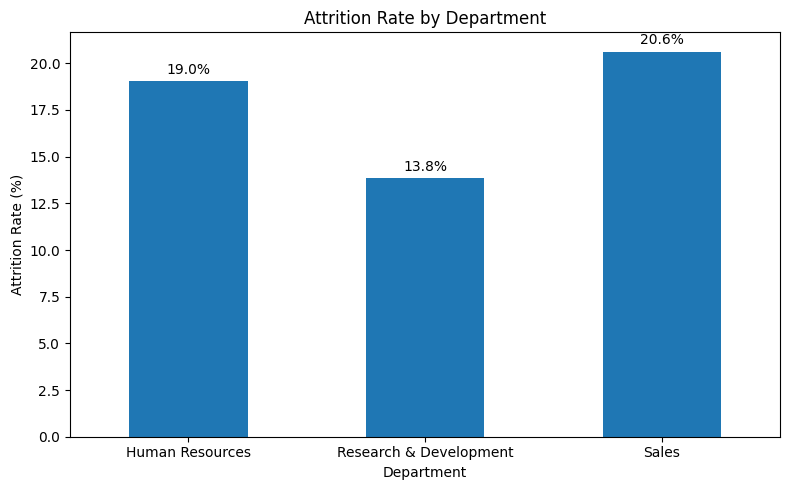

In [86]:
ax = attrition_by_dept['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

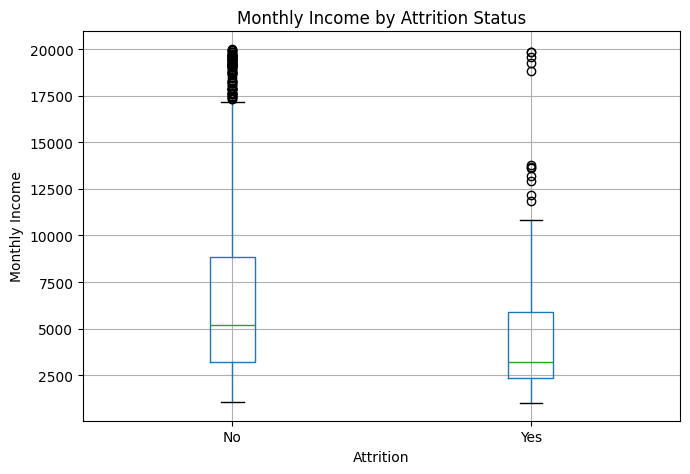

In [87]:
df.boxplot(column='MonthlyIncome', by='Attrition', figsize=(7, 5))

plt.title('Monthly Income by Attrition Status')
plt.suptitle('')
plt.xlabel('Attrition')
plt.ylabel('Monthly Income')
plt.tight_layout()
plt.show()

In [88]:
df['EmployeeCount'].value_counts()

EmployeeCount
1    1470
Name: count, dtype: int64

In [89]:
df['Over18'].value_counts()

Over18
Y    1470
Name: count, dtype: int64

In [90]:
df['StandardHours'].value_counts()

StandardHours
80    1470
Name: count, dtype: int64

In [91]:
df_clean=df.drop(columns=['EmployeeCount','Over18','StandardHours']).copy()

In [92]:
print(df_clean.shape)
print(df.shape)
print(df_clean.columns)

(1470, 32)
(1470, 35)
Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='str')


In [93]:
print(df_clean['Attrition'].value_counts())
print("*"*50)
print(df_clean['Attrition'].value_counts(normalize=True)*100)
print("*"*50)

print(df_clean['BusinessTravel'].value_counts())
print("*"*50)
print(df_clean['BusinessTravel'].value_counts(normalize=True)*100)

Attrition
No     1233
Yes     237
Name: count, dtype: int64
**************************************************
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64
**************************************************
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
**************************************************
BusinessTravel
Travel_Rarely        70.952381
Travel_Frequently    18.843537
Non-Travel           10.204082
Name: proportion, dtype: float64


In [94]:
print(df_clean['Department'].value_counts())
print("*"*100)
print(df_clean['EducationField'].value_counts())
print("*"*100)
print(df_clean['Gender'].value_counts())
print("*"*100)
print(df_clean['JobRole'].value_counts())
print("*"*100)
print(df_clean['MaritalStatus'].value_counts())
print("*"*100)
print(df_clean['OverTime'].value_counts())
print("*"*100)

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
****************************************************************************************************
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64
****************************************************************************************************
Gender
Male      882
Female    588
Name: count, dtype: int64
****************************************************************************************************
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype:

In [95]:
cols_to_check = [
    'Education',
    'EnvironmentSatisfaction',
    'JobInvolvement',
    'JobLevel',
    'JobSatisfaction',
    'PerformanceRating',
    'RelationshipSatisfaction',
    'StockOptionLevel',
    'WorkLifeBalance'
]

for col in cols_to_check:
    print(f"\n{col}")
    print(sorted(df_clean[col].unique()))


Education
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

EnvironmentSatisfaction
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

JobInvolvement
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

JobLevel
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

JobSatisfaction
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

PerformanceRating
[np.int64(3), np.int64(4)]

RelationshipSatisfaction
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

StockOptionLevel
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

WorkLifeBalance
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [96]:
numeric_cols = [
    'Age',
    'DailyRate',
    'DistanceFromHome',
    'HourlyRate',
    'MonthlyIncome',
    'MonthlyRate',
    'NumCompaniesWorked',
    'PercentSalaryHike',
    'TotalWorkingYears',
    'TrainingTimesLastYear',
    'YearsAtCompany',
    'YearsInCurrentRole',
    'YearsSinceLastPromotion',
    'YearsWithCurrManager'
]

df_clean[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
MonthlyIncome,1470.0,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.00,19999.0
MonthlyRate,1470.0,14313.103401,7117.786044,2094.0,8047.0,14235.5,20461.50,26999.0
NumCompaniesWorked,1470.0,2.693197,2.498009,0.0,1.0,2.0,4.00,9.0
PercentSalaryHike,1470.0,15.209524,3.659938,11.0,12.0,14.0,18.00,25.0
TotalWorkingYears,1470.0,11.279592,7.780782,0.0,6.0,10.0,15.00,40.0
TrainingTimesLastYear,1470.0,2.799320,1.289271,0.0,2.0,3.0,3.00,6.0


In [97]:
df_clean[df_clean["YearsAtCompany"]>df_clean["TotalWorkingYears"]][["EmployeeNumber","YearsAtCompany","TotalWorkingYears"]]

,EmployeeNumber,YearsAtCompany,TotalWorkingYears


In [98]:
df_clean[df_clean["YearsInCurrentRole"]>df_clean["YearsAtCompany"]][["EmployeeNumber","YearsAtCompany","YearsInCurrentRole"]]

,EmployeeNumber,YearsAtCompany,YearsInCurrentRole


In [99]:
df_clean[df_clean["YearsWithCurrManager"]>df_clean["YearsInCurrentRole"]][["EmployeeNumber","YearsAtCompany","YearsInCurrentRole"]]

,EmployeeNumber,YearsAtCompany,YearsInCurrentRole
0,1,6,4
8,12,9,7
11,15,9,5
12,16,5,2
14,19,4,2
...,...,...,...
1451,2041,10,7
1463,2057,9,4
1465,2061,5,2
1467,2064,6,2


In [100]:
len(
    df_clean[
        df_clean["YearsWithCurrManager"] >
        df_clean["YearsInCurrentRole"]
    ]
)

375

In [101]:
print("Shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Shape: (1470, 32)
Missing values: 0
Duplicate rows: 0


In [102]:
#does job role have an impact on attrition?
attrition_by_jobrole = df_clean.groupby('JobRole')['Attrition'].value_counts(normalize=True).unstack()*100
attrition_by_jobrole

Attrition,No,Yes
JobRole,,
Healthcare Representative,93.129771,6.870229
Human Resources,76.923077,23.076923
Laboratory Technician,76.061776,23.938224
Manager,95.098039,4.901961
Manufacturing Director,93.103448,6.896552
Research Director,97.500000,2.500000
Research Scientist,83.904110,16.095890
Sales Executive,82.515337,17.484663
Sales Representative,60.240964,39.759036


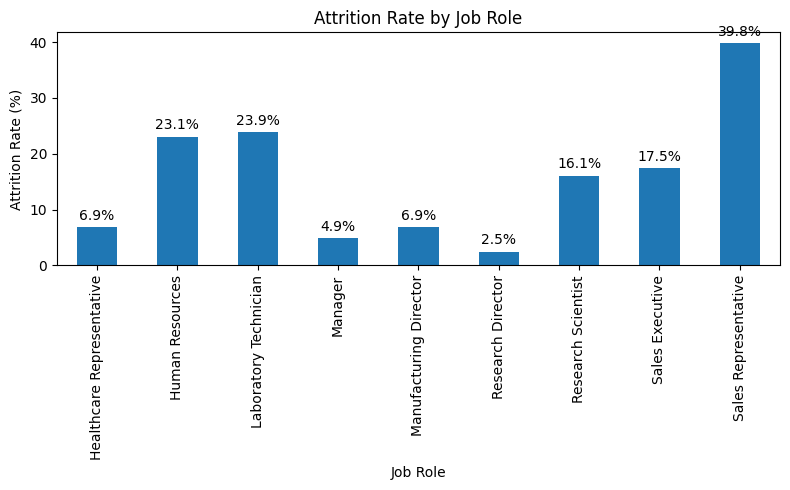

In [103]:
ax = attrition_by_jobrole['Yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.title('Attrition Rate by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Attrition Rate (%)')

plt.tight_layout()
plt.show()

### Findings:
- Sales Representatives have the highest attrition rate at 39.76%, indicating that this role may require further investigation into employee retention
- Research Directors have the lowest attrition rate at 2.50%

Is monthly income associated with attrition among Sales Representatives?

In [104]:
sales_rep = df_clean[df_clean['JobRole'] == 'Sales Representative']
sales_rep.groupby('Attrition')['MonthlyIncome'].describe()


,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,50.0,2798.440000,900.929342,1052.0,2323.75,2643.0,2971.25,6632.0
Yes,33.0,2364.727273,715.177044,1081.0,2033.00,2325.0,2785.00,4400.0


Is Job satisfaction associated with attrition among Sales Representatives?

In [105]:
sales_rep.groupby('JobSatisfaction')['Attrition'].value_counts(normalize=True).unstack()*100

Attrition,No,Yes
JobSatisfaction,,
1,41.666667,58.333333
2,52.380952,47.619048
3,66.666667,33.333333
4,69.565217,30.434783


In [106]:
sales_rep['JobSatisfaction'].value_counts()

JobSatisfaction
3    27
4    23
2    21
1    12
Name: count, dtype: int64

Are employees who workovertime more likely to leave than employees who don't amoung sales representatives?

In [107]:
sales_rep['OverTime'].value_counts()

OverTime
No     59
Yes    24
Name: count, dtype: int64

In [108]:
pd.crosstab(sales_rep['OverTime'], 
            sales_rep['Attrition'], 
            normalize='index'
        ) * 100
#the attrition percentage is about three times as high among employees who work overtime.

Attrition,No,Yes
OverTime,,
No,71.186441,28.813559
Yes,33.333333,66.666667


### Findings: Job Satisfaction and Overtime Among Sales Representatives
- Job satisfaction: Sales Representatives with satisfaction level 1 have the highest attrition rate at 58.33%, compared with 30.43% among employees with satisfaction level 4. Attrition generally decreases as job satisfaction increases.

- Overtime: Sales Representatives who work overtime have an attrition rate of 30.53%, compared with 10.44% for those who do not work overtime.

- Key insight: Both lower job satisfaction and overtime are associated with higher attrition among Sales Representatives.

In [109]:
pd.crosstab(
    df_clean['Department'],
    df_clean['Attrition'],
    normalize='index'
) * 100

Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


Are employees with lower work-life balance ratings more likely to leave the company?

In [110]:
df_clean['WorkLifeBalance'].value_counts()

WorkLifeBalance
3    893
2    344
4    153
1     80
Name: count, dtype: int64

In [111]:
pd.crosstab(
    df_clean['WorkLifeBalance'],
    df_clean['Attrition'],
    normalize='index'
) * 100
#lower work-life balance ratings are associated with higher attrition rates. 

Attrition,No,Yes
WorkLifeBalance,,
1,68.750000,31.250000
2,83.139535,16.860465
3,85.778275,14.221725
4,82.352941,17.647059


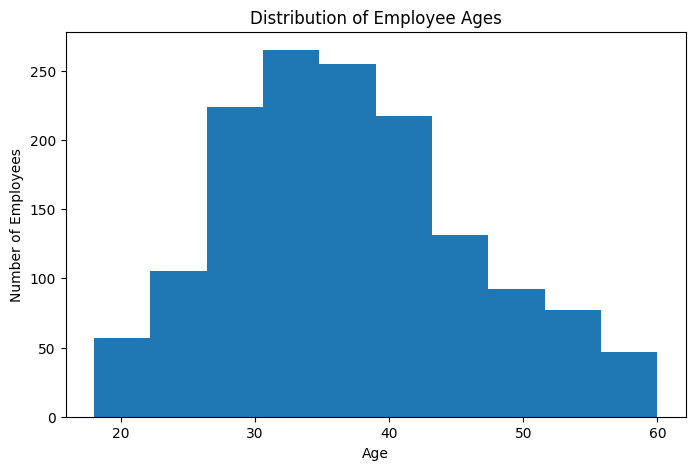

In [112]:
plt.figure(figsize=(8, 5))
plt.hist(df_clean['Age'], bins=10)
plt.xlabel('Age')
plt.ylabel('Number of Employees')
plt.title('Distribution of Employee Ages')
plt.show()

In [113]:
#which age group has the highest attrition rate?
df_clean['AgeGroup'] = pd.cut(
    df_clean['Age'],
    bins=[18,24,34,44,54,60],
    labels=['18-24','25-34','35-44','45-54','55+']
)

In [114]:
df_clean['AgeGroup'].value_counts().sort_index()

AgeGroup
18-24     89
25-34    554
35-44    505
45-54    245
55+       69
Name: count, dtype: int64

In [115]:
df_clean.groupby('AgeGroup')['Attrition'].value_counts(normalize=True).unstack()*100

Attrition,No,Yes
AgeGroup,,
18-24,61.797753,38.202247
25-34,79.783394,20.216606
35-44,89.900990,10.099010
45-54,89.795918,10.204082
55+,84.057971,15.942029


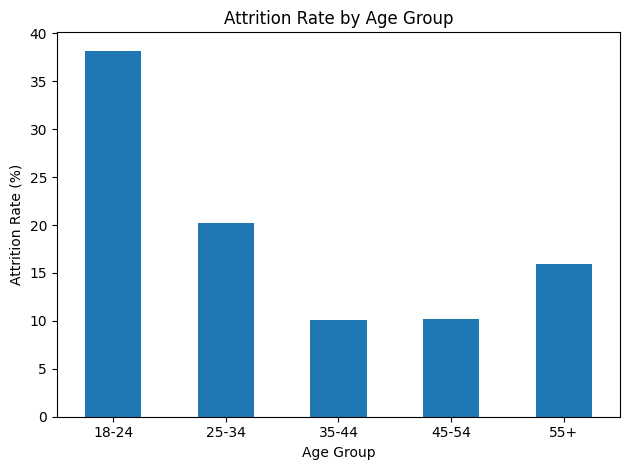

In [116]:

age_attrition = df_clean.groupby('AgeGroup')['Attrition'].value_counts(normalize=True).unstack()*100
age_attrition['Yes'].plot(kind='bar')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')
plt.title('Attrition Rate by Age Group')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Finding: Age and Attrition

- Employees aged **18–24 have the highest attrition rate at 38.20%**.
- investigate this age group further by examining salary and job satisfaction.
- Further analysis is needed to understand whether these factors are associated with attrition among younger employees.

In [117]:
#Does attrition differ based on YearsAtCompany?

years_attrition = df_clean.groupby('YearsAtCompany')['Attrition'].value_counts(normalize=True).unstack()*100
years_attrition

Attrition,No,Yes
YearsAtCompany,,
0,63.636364,36.363636
1,65.497076,34.502924
2,78.740157,21.259843
3,84.375000,15.625000
4,82.727273,17.272727
5,89.285714,10.714286
6,88.157895,11.842105
7,87.777778,12.222222
8,88.750000,11.250000


In [118]:
df_clean['TenureGroup'] = pd.cut(
    df_clean['YearsAtCompany'],
    bins=[-1, 1, 5, 10, 40],
    labels=['0-1', '2-5', '6-10', '11+']
)
df_clean['TenureGroup'].value_counts().sort_index()

TenureGroup
0-1     215
2-5     561
6-10    448
11+     246
Name: count, dtype: int64

In [119]:
pd.crosstab(
    df_clean['TenureGroup'],
    df_clean['Attrition'],
    normalize='index'
) * 100

Attrition,No,Yes
TenureGroup,,
0-1,65.116279,34.883721
2-5,84.491979,15.508021
6-10,87.723214,12.276786
11+,91.869919,8.130081


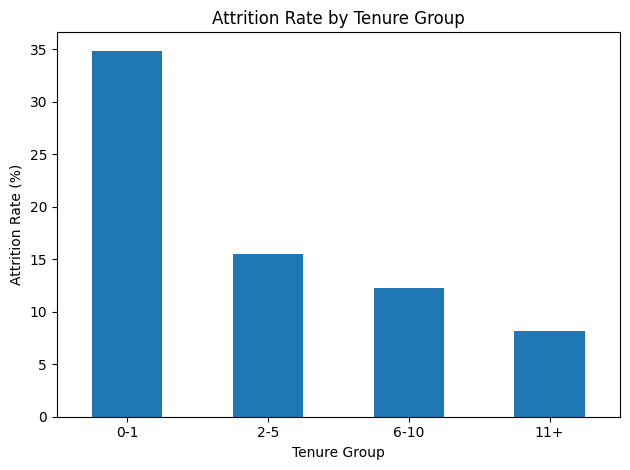

In [120]:
tenure_attrition = df_clean.groupby('TenureGroup')['Attrition'].value_counts(normalize=True).unstack()*100
tenure_attrition['Yes'].plot(kind='bar')
plt.xlabel('Tenure Group')
plt.ylabel('Attrition Rate (%)')
plt.title('Attrition Rate by Tenure Group')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Finding: Tenure and Attrition

- Employees with 0–1 years at the company have the highest attrition rate (34.88%).
- Attrition decreases across the tenure groups, reaching 8.13% among employees with 11+ years of tenure.
- HR should investigate the early employee experience, including onboarding, job satisfaction, and compensation, to better understand this pattern.

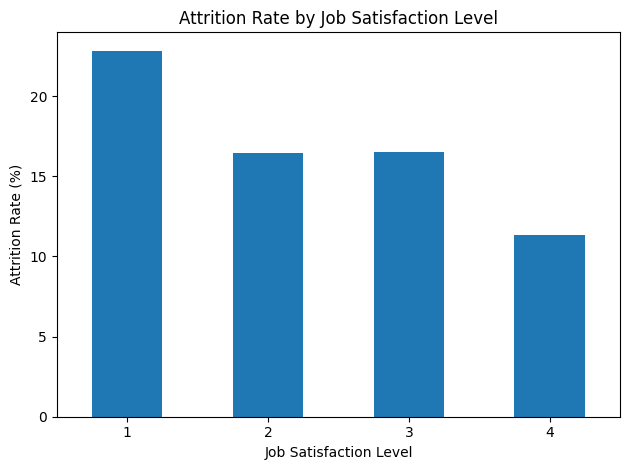

In [121]:
job_satisfaction = pd.crosstab(
    df_clean['JobSatisfaction'],
    df_clean['Attrition'],
    normalize='index'
) * 100
job_satisfaction['Yes'].plot(kind='bar')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.title('Attrition Rate by Job Satisfaction Level')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [122]:
pd.crosstab(
    df_clean['JobSatisfaction'],
    df_clean['Attrition']
)

Attrition,No,Yes
JobSatisfaction,,
1,223,66
2,234,46
3,369,73
4,407,52


### Key Finding: Job Satisfaction and Attrition

- Employees with job satisfaction level 1 have the highest attrition rate at **22.84%**, while level 4 has the lowest at **11.33%**.
- Attrition is generally higher among employees reporting lower job satisfaction, although levels 2 and 3 show similar rates.
- This suggests an association between job satisfaction and attrition, but it does not establish causation.

Do employees who live farther from work have different attrition rates?

In [123]:
df_clean['DistanceGroup'] = pd.cut(
    df_clean['DistanceFromHome'],
    bins=[0, 5, 15, 30],
    labels=['Near', 'Moderate', 'Far']
)
df_clean['DistanceGroup'].value_counts().sort_index()


DistanceGroup
Near        632
Moderate    509
Far         329
Name: count, dtype: int64

In [124]:
pd.crosstab(
    df_clean['DistanceGroup'],
    df_clean['Attrition'],
    normalize='index'
)*100

Attrition,No,Yes
DistanceGroup,,
Near,86.234177,13.765823
Moderate,83.889980,16.110020
Far,79.331307,20.668693


In [125]:
df_clean['DistanceGroup'].value_counts().sort_index()

DistanceGroup
Near        632
Moderate    509
Far         329
Name: count, dtype: int64

### Key Finding: Distance from Home and Attrition

Employees in the Far distance group have the highest attrition rate (20.67%), compared with 13.77% in the Near group. Attrition rates increase across the three distance groups. This suggests an association between distance from home and attrition, although further analysis is needed to investigate possible explanations.

In [126]:
#Do employees who travel for business more frequently have different attrition rates?
#df_clean['BusinessTravel'].value_counts()
df_clean.groupby('BusinessTravel')['Attrition'].value_counts(normalize=True).unstack()*100

Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.000000,8.000000
Travel_Frequently,75.090253,24.909747
Travel_Rarely,85.043145,14.956855


### Key Finding: Business Travel and Attrition

Employees who travel frequently for business have the highest attrition rate (24.91%), compared with 14.96% among employees who travel rarely and 8.00% among employees who do not travel. This pattern suggests an association between business travel frequency and attrition, but further analysis is needed to investigate possible explanations.

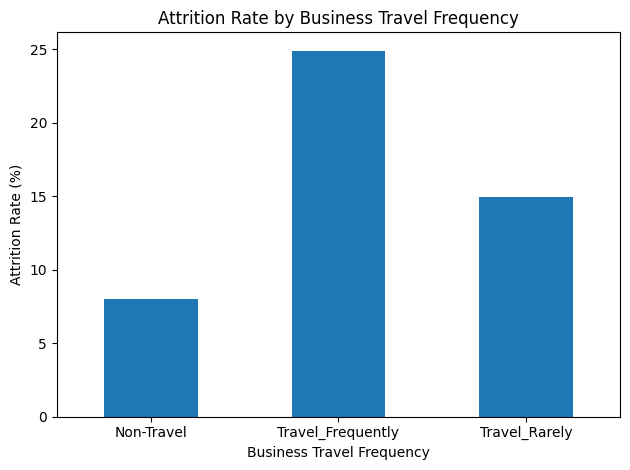

In [127]:
buisiness_travel_attrition = df_clean.groupby('BusinessTravel')['Attrition'].value_counts(normalize=True).unstack()*100
buisiness_travel_attrition['Yes'].plot(kind='bar')
plt.xlabel('Business Travel Frequency')
plt.ylabel('Attrition Rate (%)')
plt.title('Attrition Rate by Business Travel Frequency')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [128]:
#do employees with different levels of EnvironmentSatisfaction have different attrition rates?
df_clean['EnvironmentSatisfaction'].value_counts()

EnvironmentSatisfaction
3    453
4    446
2    287
1    284
Name: count, dtype: int64

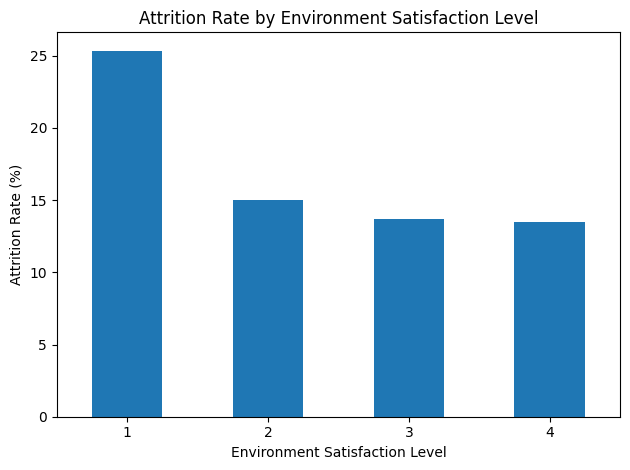

In [129]:
environment_satisfaction_attrition = pd.crosstab(
    df_clean['EnvironmentSatisfaction'],
    df_clean['Attrition'],
    normalize='index'
)*100
environment_satisfaction_attrition['Yes'].plot(kind='bar')
plt.xlabel('Environment Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.title('Attrition Rate by Environment Satisfaction Level')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [130]:
environment_satisfaction_attrition 

Attrition,No,Yes
EnvironmentSatisfaction,,
1,74.647887,25.352113
2,85.017422,14.982578
3,86.313466,13.686534
4,86.547085,13.452915


 ### Findings
 Employees with the lowest environment satisfaction rating had the highest attrition rate (25.35%), compared with 13.45% among employees with the highest rating.

In [131]:
# does employees with higher relationship satisfaction have lower attrition rates?
df_clean['RelationshipSatisfaction'].value_counts()

RelationshipSatisfaction
3    459
4    432
2    303
1    276
Name: count, dtype: int64

In [132]:
pd.crosstab(
    df_clean['RelationshipSatisfaction'],
    df_clean['Attrition'],
    normalize='index'
)*100

Attrition,No,Yes
RelationshipSatisfaction,,
1,79.347826,20.652174
2,85.148515,14.851485
3,84.531590,15.468410
4,85.185185,14.814815


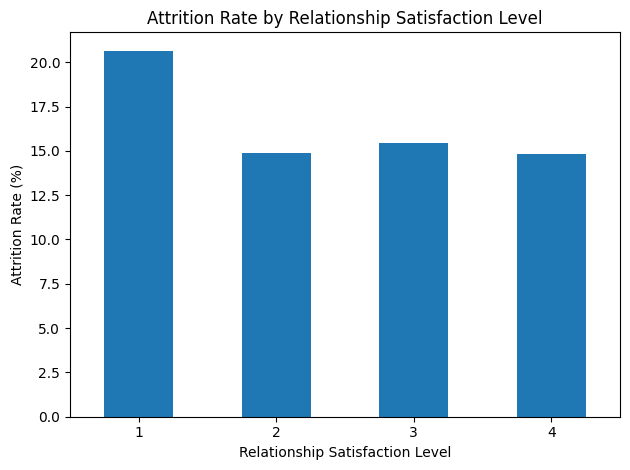

In [133]:
relationship_satisfaction_attrition = pd.crosstab(
    df_clean['RelationshipSatisfaction'],
    df_clean['Attrition'],
    normalize='index'
)*100
relationship_satisfaction_attrition['Yes'].plot(kind='bar')
plt.xlabel('Relationship Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.title('Attrition Rate by Relationship Satisfaction Level')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Findings:
Employees with the lowest relationship satisfaction rating had the highest attrition rate (20.65%), while the other satisfaction levels had rates around 14.81%–15.47%.

In [134]:
#does employees with more years since last promotion have higher attrition rates?
df_clean['YearsSinceLastPromotion'].value_counts().sort_index()

YearsSinceLastPromotion
0     581
1     357
2     159
3      52
4      61
5      45
6      32
7      76
8      18
9      17
10      6
11     24
12     10
13     10
14      9
15     13
Name: count, dtype: int64

In [135]:
promotion_attrition = pd.crosstab(
    df_clean['YearsSinceLastPromotion'],
    df_clean['Attrition'],
    normalize='index'
) * 100

promotion_attrition
#no consistent increasing or decreasing pattern across the individual years

Attrition,No,Yes
YearsSinceLastPromotion,,
0,81.067126,18.932874
1,86.274510,13.725490
2,83.018868,16.981132
3,82.692308,17.307692
4,91.803279,8.196721
5,95.555556,4.444444
6,81.250000,18.750000
7,78.947368,21.052632
8,100.000000,0.000000


In [136]:
df_clean['PromotionGroup'] = pd.cut(
    df_clean['YearsSinceLastPromotion'],
    bins=[-1, 2, 5, 15],
    labels=['0-2 years', '3-5 years', '6+ years']
)
promotion_group_attrition = pd.crosstab(
    df_clean['PromotionGroup'],
    df_clean['Attrition'],
    normalize='index'
) * 100

promotion_group_attrition

Attrition,No,Yes
PromotionGroup,,
0-2 years,83.044667,16.955333
3-5 years,89.873418,10.126582
6+ years,83.720930,16.279070


### Findings:
Employees who had gone 0–2 years or 6+ years since their last promotion had higher attrition rates (16.96% and 16.28%, respectively) than employees in the 3–5 years group (10.13%).

In [137]:
df_clean['StockOptionLevel'].value_counts().sort_index()

StockOptionLevel
0    631
1    596
2    158
3     85
Name: count, dtype: int64

In [138]:
pd.crosstab(
    df_clean['StockOptionLevel'],
    df_clean['Attrition'],
    normalize='index'
) * 100

Attrition,No,Yes
StockOptionLevel,,
0,75.594295,24.405705
1,90.604027,9.395973
2,92.405063,7.594937
3,82.352941,17.647059


### Findings:
Employees with StockOptionLevel 0 had the highest attrition rate (24.41%), compared with 9.40% at level 1 and 7.59% at level 2. The rate increased to 17.65% at level 3.

In [139]:
df_clean['NumCompaniesWorked'].value_counts().sort_index()

NumCompaniesWorked
0    197
1    521
2    146
3    159
4    139
5     63
6     70
7     74
8     49
9     52
Name: count, dtype: int64

In [140]:
pd.crosstab(
    df_clean['NumCompaniesWorked'],
    df_clean['Attrition'],
    normalize='index'
) * 100

Attrition,No,Yes
NumCompaniesWorked,,
0,88.324873,11.675127
1,81.190019,18.809981
2,89.041096,10.958904
3,89.937107,10.062893
4,87.769784,12.230216
5,74.603175,25.396825
6,77.142857,22.857143
7,77.027027,22.972973
8,87.755102,12.244898


### Findings:
Employees who had previously worked at five companies had the highest attrition rate (25.40%). Relatively high attrition rates were also observed among employees with six, seven, and nine previous companies. However, the relationship was not consistent across all groups.